Mounted at /content/drive
Dataset successfully loaded. Total samples: 799
Target distribution:
YLD_Hotspot_Flag
0    777
1     22
Name: count, dtype: int64

5-Fold Stratified CV F1-Score: 0.9152 (+/- 0.0431)

--- Test Set Classification Report (XGBoost) ---
                precision    recall  f1-score   support

Stable/Healthy       1.00      1.00      1.00       156
   YLD Hotspot       1.00      1.00      1.00         4

      accuracy                           1.00       160
     macro avg       1.00      1.00      1.00       160
  weighted avg       1.00      1.00      1.00       160

Test ROC-AUC Score: 1.0000


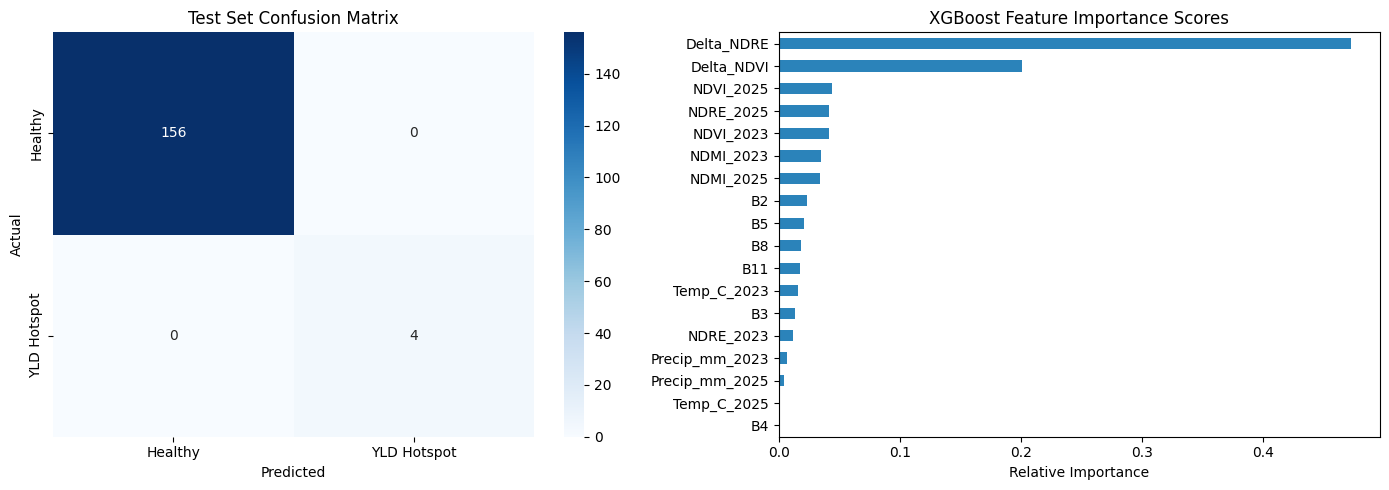

Model artifacts saved to Google Drive.


In [ ]:
# ==========================================
# 1. ENVIRONMENT SETUP & DATA INGESTION
# ==========================================
from google.colab import drive
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import xgboost as xgb

drive.mount('/content/drive')

csv_file = '/content/drive/MyDrive/Arecanut_YLD_Project/Sringeri_YLD_ML_Features.csv'
df = pd.read_csv(csv_file)

# Drop system indices and GeoJSON strings
cols_to_remove = ['.geo', 'system:index']
df = df.drop(columns=[c for c in cols_to_remove if c in df.columns]).dropna()

print(f"Dataset successfully loaded. Total samples: {len(df)}")

# ==========================================
# 2. FEATURE MATRIX & TARGET DEFINITION
# ==========================================
# Target: YLD_Hotspot_Flag (1 = Severe Chronic Decline / YLD Risk, 0 = Healthy / Stable)
target_col = 'YLD_Hotspot_Flag'

feature_cols = [
    'B2', 'B3', 'B4', 'B5', 'B8', 'B11',
    'NDVI_2023', 'NDRE_2023', 'NDMI_2023', 'Temp_C_2023', 'Precip_mm_2023',
    'NDVI_2025', 'NDRE_2025', 'NDMI_2025', 'Temp_C_2025', 'Precip_mm_2025',
    'Delta_NDRE', 'Delta_NDVI'
]

X = df[feature_cols]
y = df[target_col].astype(int)

print(f"Target distribution:\n{y.value_counts()}")

# Stratified Train/Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# ==========================================
# 3. MODEL TRAINING: RANDOM FOREST & XGBOOST
# ==========================================
# Model 1: Random Forest
rf_clf = RandomForestClassifier(n_estimators=150, max_depth=6, random_state=42)
rf_clf.fit(X_train, y_train)

# Model 2: XGBoost Classifier
xgb_clf = xgb.XGBClassifier(
    n_estimators=150,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42
)
xgb_clf.fit(X_train, y_train)

# ==========================================
# 4. CROSS VALIDATION & TEST EVALUATION
# ==========================================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(xgb_clf, X, y, cv=cv, scoring='f1')
print(f"\n5-Fold Stratified CV F1-Score: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

y_pred_xgb = xgb_clf.predict(X_test)
y_prob_xgb = xgb_clf.predict_proba(X_test)[:, 1]

print("\n--- Test Set Classification Report (XGBoost) ---")
print(classification_report(y_test, y_pred_xgb, target_names=['Stable/Healthy', 'YLD Hotspot']))
print(f"Test ROC-AUC Score: {roc_auc_score(y_test, y_prob_xgb):.4f}")

# ==========================================
# 5. DIAGNOSTIC PLOTS & EXPORTS
# ==========================================
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Plot A: Confusion Matrix
sns.heatmap(confusion_matrix(y_test, y_pred_xgb), annot=True, fmt='d', cmap='Blues', ax=ax[0],
            xticklabels=['Healthy', 'YLD Hotspot'], yticklabels=['Healthy', 'YLD Hotspot'])
ax[0].set_title('Test Set Confusion Matrix')
ax[0].set_xlabel('Predicted')
ax[0].set_ylabel('Actual')

# Plot B: Feature Importance
importances = pd.Series(xgb_clf.feature_importances_, index=feature_cols).sort_values()
importances.plot(kind='barh', ax=ax[1], color='#2b83ba')
ax[1].set_title('XGBoost Feature Importance Scores')
ax[1].set_xlabel('Relative Importance')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/Arecanut_YLD_Project/model_diagnostics.png', dpi=300)
plt.show()

# Save Trained Model
joblib.dump(xgb_clf, '/content/drive/MyDrive/Arecanut_YLD_Project/sringeri_xgb_model.pkl')
print("Model artifacts saved to Google Drive.")

Raster Dimensions: 2228 x 1671 across 19 bands
Running inference across 3,722,988 pixels...
Spatial risk prediction complete! Saved as 'Sringeri_YLD_XGBoost_Probability_Map.tif'


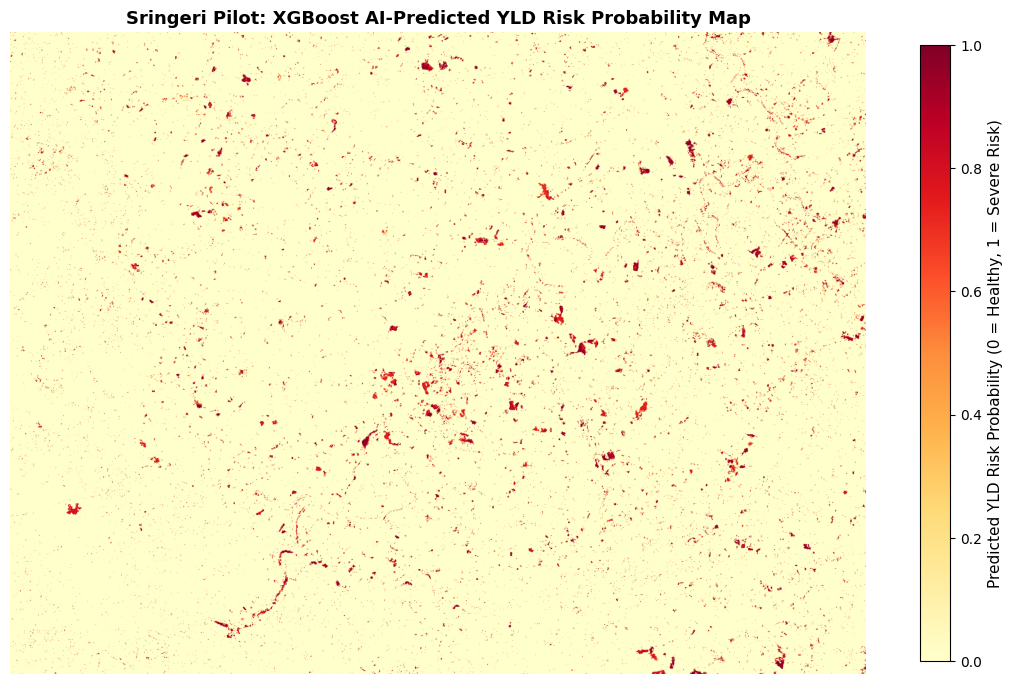

In [ ]:
import rasterio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the 19-band GeoTIFF
tif_path = '/content/drive/MyDrive/Arecanut_YLD_Project/Sringeri_YLD_Master_Raster.tif'

with rasterio.open(tif_path) as src:
    profile = src.profile
    img_data = src.read()  # Shape: (19, height, width)

bands, height, width = img_data.shape
print(f"Raster Dimensions: {width} x {height} across {bands} bands")

# 2. Reshape into 2D table for ML prediction (pixels x bands)
flat_img = img_data.reshape(bands, -1).T

# 3. Exactly 19 columns: 18 features + 1 target mask
all_band_names = feature_cols + ['YLD_Hotspot_Flag']
df_inference = pd.DataFrame(flat_img, columns=all_band_names)

# Extract only the 18 predictor features the model was trained on
X_inf = df_inference[feature_cols].fillna(0)

# 4. Batch Predict Using the Trained XGBoost Model
print(f"Running inference across {len(X_inf):,} pixels...")
risk_preds = xgb_clf.predict_proba(X_inf)[:, 1]  # Probability of YLD disease risk

# 5. Reshape back into 2D spatial grid
risk_map = risk_preds.reshape(height, width)

# 6. Export Predicted Probability Map as a GeoTIFF to Drive
profile.update(dtype=rasterio.float32, count=1)

output_tif = '/content/drive/MyDrive/Arecanut_YLD_Project/Sringeri_YLD_XGBoost_Probability_Map.tif'
with rasterio.open(output_tif, 'w', **profile) as dst:
    dst.write(risk_map.astype(rasterio.float32), 1)

print("Spatial risk prediction complete! Saved as 'Sringeri_YLD_XGBoost_Probability_Map.tif'")

# 7. Visualize the Predicted Risk Map
plt.figure(figsize=(11, 8))
plt.imshow(risk_map, cmap='YlOrRd', vmin=0, vmax=1)
cbar = plt.colorbar(shrink=0.8)
cbar.set_label('Predicted YLD Risk Probability (0 = Healthy, 1 = Severe Risk)', fontsize=11)
plt.title('Sringeri Pilot: XGBoost AI-Predicted YLD Risk Probability Map', fontsize=13, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

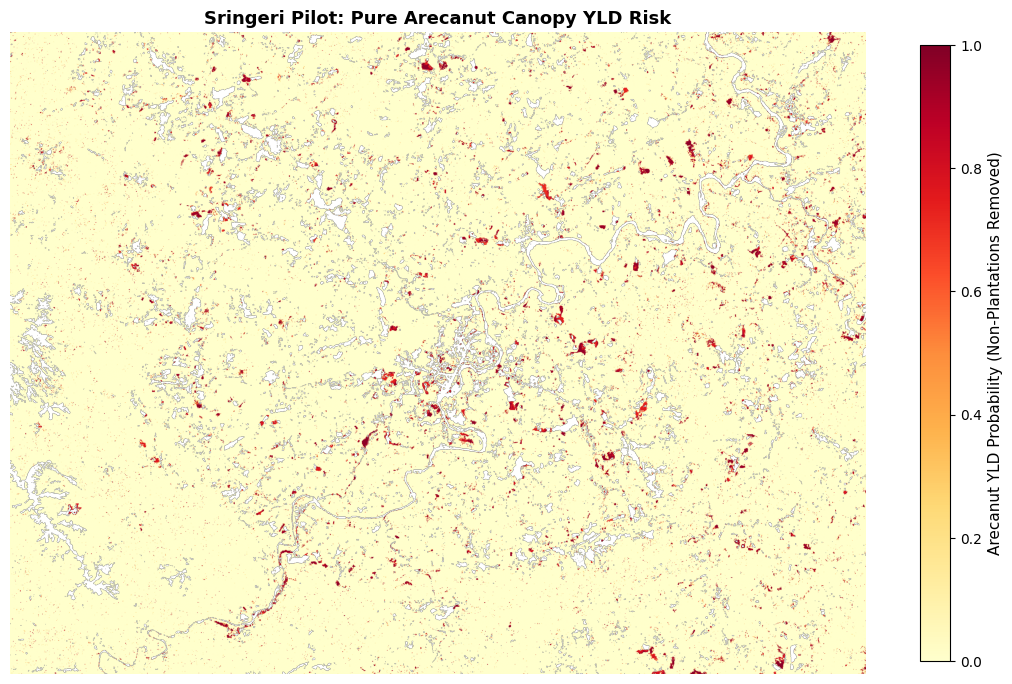

In [ ]:
# Isolate only true agricultural vegetation (NDVI > 0.45)
ndvi_2023 = img_data[feature_cols.index('NDVI_2023')]
masked_risk_map = np.where(ndvi_2023 > 0.45, risk_map, np.nan)

plt.figure(figsize=(11, 8))
plt.imshow(masked_risk_map, cmap='YlOrRd', vmin=0, vmax=1)
cbar = plt.colorbar(shrink=0.8)
cbar.set_label('Arecanut YLD Probability (Non-Plantations Removed)', fontsize=11)
plt.title('Sringeri Pilot: Pure Arecanut Canopy YLD Risk', fontsize=13, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
!pip install folium rasterio

import folium
import rasterio
import numpy as np

# 1. Open the probability map exported to your Drive
tif_path = '/content/drive/MyDrive/Arecanut_YLD_Project/Sringeri_YLD_XGBoost_Probability_Map.tif'

with rasterio.open(tif_path) as src:
    bounds = src.bounds
    # Calculate center coordinates [lat, lon]
    center_lat = (bounds.bottom + bounds.top) / 2
    center_lon = (bounds.left + bounds.right) / 2

# 2. Create interactive Folium map centered on Sringeri
m = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=12,
    tiles='https://mt1.google.com/vt/lyrs=y&x={x}&y={y}&z={z}',
    attr='Google Satellite Hybrid'
)

# 3. Add bounding box and location marker
folium.Rectangle(
    bounds=[[bounds.bottom, bounds.left], [bounds.top, bounds.right]],
    color='#e41a1c',
    weight=2,
    fill=False,
    popup="Sringeri YLD Pilot Study Area"
).add_to(m)

# Display interactive map directly inside Colab
m